# MNIST Digit Classification with TensorFlow and Keras

## 1. Install TensorFlow
Run this cell if TensorFlow is not already installed. In Google Colab, it is usually preinstalled.

In [ ]:
#%pip install -q tensorflow

## 2. Import libraries

In [ ]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout   #DENSE means fully connected
from tensorflow.keras.optimizers import Adam

## 3. Load the MNIST dataset
MNIST contains 60,000 training images and 10,000 test images. Each grayscale image is 28 × 28 pixels.

In [ ]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print('Training images:', X_train.shape)
print('Training labels:', y_train.shape)
print('Testing images:', X_test.shape)
print('Testing labels:', y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


## 4. Display a sample image

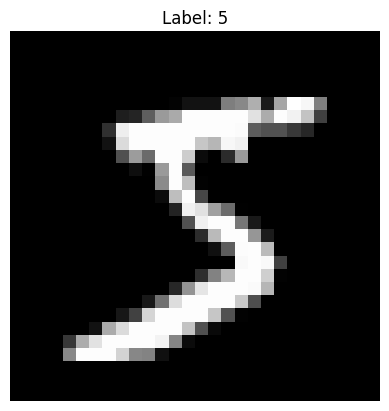

In [ ]:
plt.imshow(X_train[0], cmap='gray')
plt.title(f'Label: {y_train[0]}')
plt.axis('off')
plt.show()

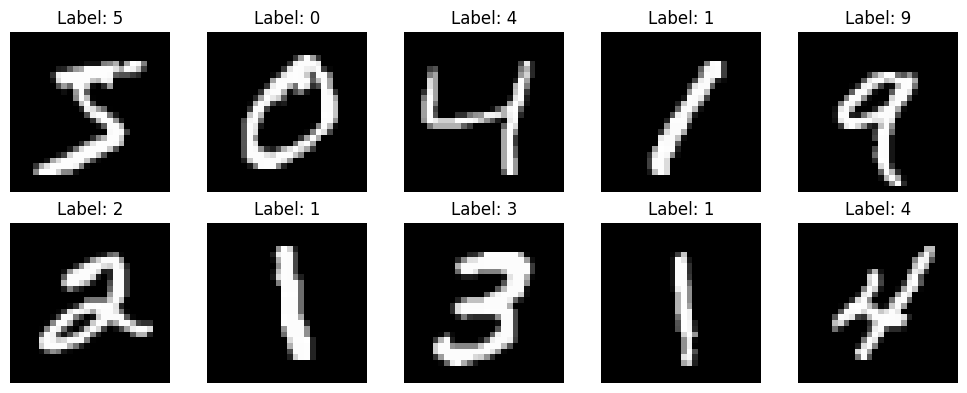

In [ ]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f'Label: {y_train[i]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

## 5. Preprocess the data
Scale pixel values from 0–255 to 0–1. The model's `Flatten` layer will reshape each image.

In [ ]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

## 6. Build the neural network
The model uses a flattening layer, a 128-neuron hidden layer, dropout, and a 10-class softmax output.

In [ ]:
model=Sequential([
    Flatten(input_shape=(28,28)),   # Comvert 28*28 image into 784 dimensional vector
    Dense(128,activation='relu'),   # hidden layer 1
    Dense(64,activation='relu'),   # hidden layer 2
    Dense(10,activation='softmax')])    # output layer  - there are 10 classes in the output

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#model = Sequential([
#    layers.Input(shape=(28, 28)),
#    layers.Flatten(),
#    layers.Dense(128, activation='relu'),
#    layers.Dropout(0.2),
#    layers.Dense(10, activation='softmax')])



## 7. Compile the model

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 8. Train the model
The notebook trains for 10 epochs and uses 10% of the training data for validation.

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8945 - loss: 0.3777 - val_accuracy: 0.9492 - val_loss: 0.1808
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9544 - loss: 0.1539 - val_accuracy: 0.9607 - val_loss: 0.1366
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9679 - loss: 0.1075 - val_accuracy: 0.9668 - val_loss: 0.1143
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9760 - loss: 0.0820 - val_accuracy: 0.9676 - val_loss: 0.1094
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9810 - loss: 0.0637 - val_accuracy: 0.9718 - val_loss: 0.0958
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9841 - loss: 0.0529 - val_accuracy: 0.9704 - val_loss: 0.1023
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9866 - loss: 0.0432 - val_accuracy: 0.9707 - val_loss: 0.0999
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9887 - loss: 0.0361 - val_accuracy: 0.

## 9. Evaluate on the test set

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy * 100:.2f}%')

Test loss: 0.0947
Test accuracy: 97.39%


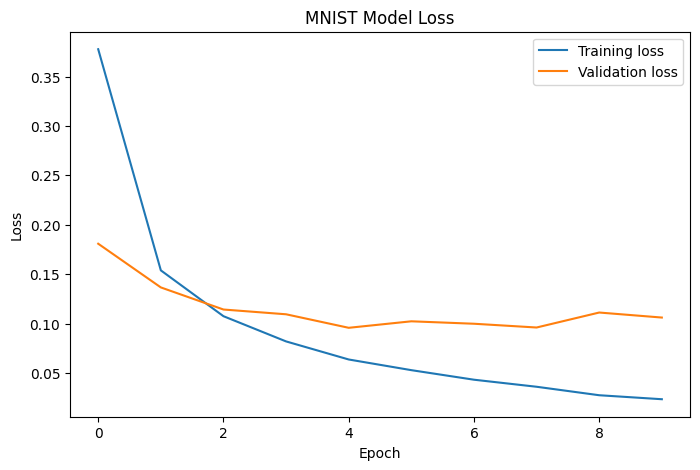

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('MNIST Model Loss')
plt.legend()

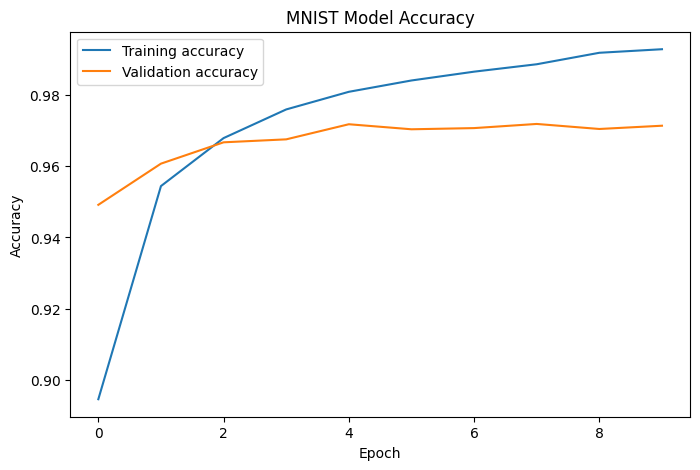

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('MNIST Model Accuracy')
plt.legend()

## 10. Predict digits
Display predictions for the first five test images.

In [ ]:
predictions = model.predict(X_test)

predicted_labels = np.argmax(predictions, axis=1)

for i in range(5):
    print(f'Actual: {y_test[i]}, Predicted: {predicted_labels[i]}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Actual: 7, Predicted: 7
Actual: 2, Predicted: 2
Actual: 1, Predicted: 1
Actual: 0, Predicted: 0
Actual: 4, Predicted: 4


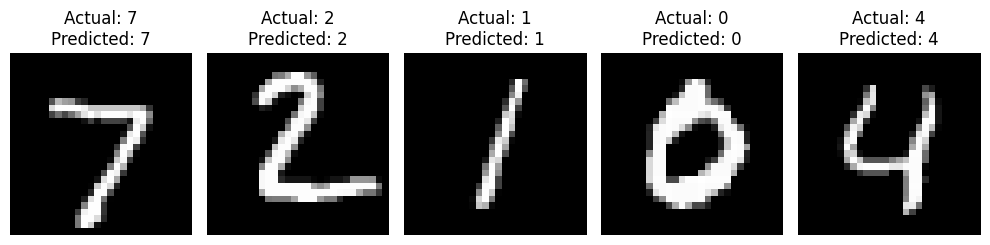

In [ ]:
plt.figure(figsize=(10, 4))
for i in range(5):
    predicted_label = int(np.argmax(predictions[i]))
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i], cmap='gray')
    plt.title(f'Actual: {y_test[i]}\nPredicted: {predicted_label}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## 11. Plot training and validation accuracy

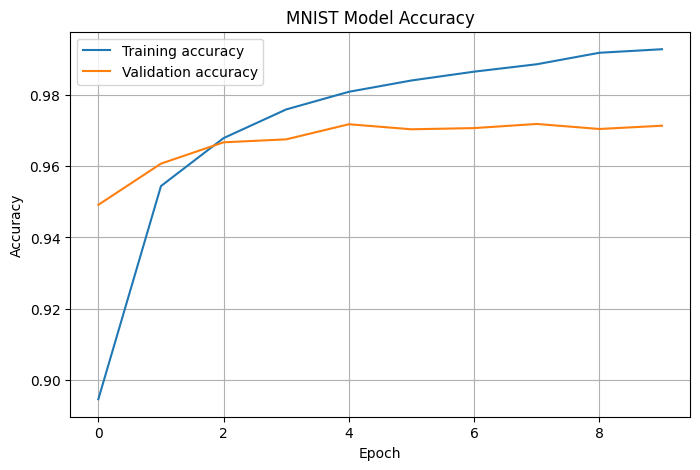

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('MNIST Model Accuracy')
plt.legend()
plt.grid(True)
plt.show()

## 12. Save the trained model (optional)
Uncomment the next line to save the model in Keras format.

In [ ]:
# model.save('mnist_digit_classifier.keras')